In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math

In [2]:
df = pd.read_csv('trip_data.csv', low_memory=False)

In [3]:
df.head(15)

,HOUSEID,PERSONID,TRPTRANS,TRVLCMIN,TRPMILES,DWELTIME,WHYTO,TRAVDAY,URBRUR,R_AGE,...,WORKER,EDUC,PAYPROF,CAN-DRIVER,SEX,HHFAMINC,HHVEHCNT,HHSIZE,URBAN,HOMEOWN
0,30000007,1,3.0,15.0,5.244,295.0,19.0,Monday,1,67.0,...,2.0,3.0,2.0,1.0,Female,7.0,5,3,1,1.0
1,30000007,1,3.0,20.0,5.149,NaN,1.0,Monday,1,67.0,...,2.0,3.0,2.0,1.0,Female,7.0,5,3,1,1.0
2,30000007,2,6.0,120.0,84.004,540.0,1.0,Monday,1,66.0,...,1.0,3.0,NaN,1.0,Male,7.0,5,3,1,1.0
3,30000007,2,6.0,150.0,81.628,NaN,3.0,Monday,1,66.0,...,1.0,3.0,NaN,1.0,Male,7.0,5,3,1,1.0
4,30000007,3,3.0,15.0,2.250,330.0,8.0,Monday,1,28.0,...,2.0,2.0,2.0,1.0,Female,7.0,5,3,1,1.0
5,30000007,3,3.0,15.0,2.243,NaN,1.0,Monday,1,28.0,...,2.0,2.0,2.0,1.0,Female,7.0,5,3,1,1.0
6,30000008,1,6.0,15.0,8.017,720.0,3.0,Thursday,2,55.0,...,1.0,5.0,NaN,1.0,Male,8.0,4,2,4,1.0
7,30000008,1,6.0,10.0,8.017,NaN,1.0,Thursday,2,55.0,...,1.0,5.0,NaN,1.0,Male,8.0,4,2,4,1.0
8,30000012,1,4.0,15.0,3.395,55.0,16.0,Thursday,1,45.0,...,1.0,5.0,NaN,1.0,Female,10.0,2,1,1,1.0
9,30000012,1,4.0,15.0,3.395,15.0,1.0,Thursday,1,45.0,...,1.0,5.0,NaN,1.0,Female,10.0,2,1,1,1.0


In [4]:
df.isnull().sum()

HOUSEID            0
PERSONID           0
TRPTRANS          16
TRVLCMIN        1297
TRPMILES         656
DWELTIME      219200
WHYTO            232
TRAVDAY            0
URBRUR             0
R_AGE           1216
PRMACT         79373
WORKER         79323
EDUC           65579
PAYPROF       508915
CAN-DRIVER     71889
SEX              711
HHFAMINC       24340
HHVEHCNT           0
HHSIZE             0
URBAN              0
HOMEOWN          162
dtype: int64

In [5]:
df.shape

(923572, 21)

In [6]:
df.isnull().sum() / len(df) * 100

HOUSEID        0.000000
PERSONID       0.000000
TRPTRANS       0.001732
TRVLCMIN       0.140433
TRPMILES       0.071029
DWELTIME      23.733937
WHYTO          0.025120
TRAVDAY        0.000000
URBRUR         0.000000
R_AGE          0.131663
PRMACT         8.594132
WORKER         8.588719
EDUC           7.100583
PAYPROF       55.102905
CAN-DRIVER     7.783800
SEX            0.076984
HHFAMINC       2.635420
HHVEHCNT       0.000000
HHSIZE         0.000000
URBAN          0.000000
HOMEOWN        0.017541
dtype: float64

In [7]:
df = df.drop(['DWELTIME', 'PAYPROF', 'PRMACT', 'EDUC', 'URBAN'], axis=1)

In [8]:
df = df.dropna()

In [9]:
df['SEX'].unique()

array(['Female', 'Male'], dtype=object)

In [10]:
df.isnull().sum()

HOUSEID       0
PERSONID      0
TRPTRANS      0
TRVLCMIN      0
TRPMILES      0
WHYTO         0
TRAVDAY       0
URBRUR        0
R_AGE         0
WORKER        0
CAN-DRIVER    0
SEX           0
HHFAMINC      0
HHVEHCNT      0
HHSIZE        0
HOMEOWN       0
dtype: int64

In [11]:
df.columns

Index(['HOUSEID', 'PERSONID', 'TRPTRANS', 'TRVLCMIN', 'TRPMILES', 'WHYTO',
       'TRAVDAY', 'URBRUR', 'R_AGE', 'WORKER', 'CAN-DRIVER', 'SEX', 'HHFAMINC',
       'HHVEHCNT', 'HHSIZE', 'HOMEOWN'],
      dtype='object')

In [12]:
df = df.rename(columns={'CAN-DRIVER':'DRIVER', 'HHFAMINC':'HHFAMINC (AVERAGE)'})

In [13]:
df['SEX'].unique()

array(['Female', 'Male'], dtype=object)

In [14]:
df['WHYTO'] = df['WHYTO'].map({1:'home-activity', 2: 'remote-work(home)' , 3: 'remote-work(not home)',
                               4: 'work-activity-to transport' , 5: 'work-activity-other' ,
                               6: 'school' , 7: 'childcare/adultcare' , 8: 'volunteer' , 9: 'change-transpo' ,
                               10: 'personal-dropoff/pickup' , 11: 'healthcare-visit' , 12: 'buy-meals' ,
                               13: 'shop-activity' , 14: 'personal/family-errands' , 15: 'recreation' ,
                               16: 'exercise' , 17: 'visit-friends/family' , 18: 'vacation' , 
                               19:'religous-activity', 20:'none-of-above'})

df['URBRUR'] = df['URBRUR'].map({1:'Urban', 2:'Rural'})
df['WORKER'] = df['WORKER'].map({1:'Worker', 2:'Not Worker'})
df['DRIVER'] = df['DRIVER'].map({1:'Yes', 2:'No'})
df['HHFAMINC (AVERAGE)'] = df['HHFAMINC (AVERAGE)'].map({1:10000, 2: 12500, 3: 20000, 4: 30000, 5:42500, 6:62500, 7: 87500, 8: 122500, 9:137500, 10:175000, 11: 200000})
df['TRPTRANS'] = df['TRPTRANS'].map({1:'car', 2: 'van' , 3: 'suv',
                               4: 'pickup-truck'  ,
                               6: 'rec-car' , 7: 'motorcycle' , 8: 'public-bus' , 9: 'school-bus' ,
                               10: 'street-car' , 11: 'subway' , 12: 'comm-rail' ,
                               13: 'amtrak' , 14: 'airplane' , 15: 'taxi' ,
                               16: 'ride-share' , 17: 'paratransit' , 18: 'bicycle' , 
                               19:'e-scooter', 20:'walked', 21: 'noneabove' })

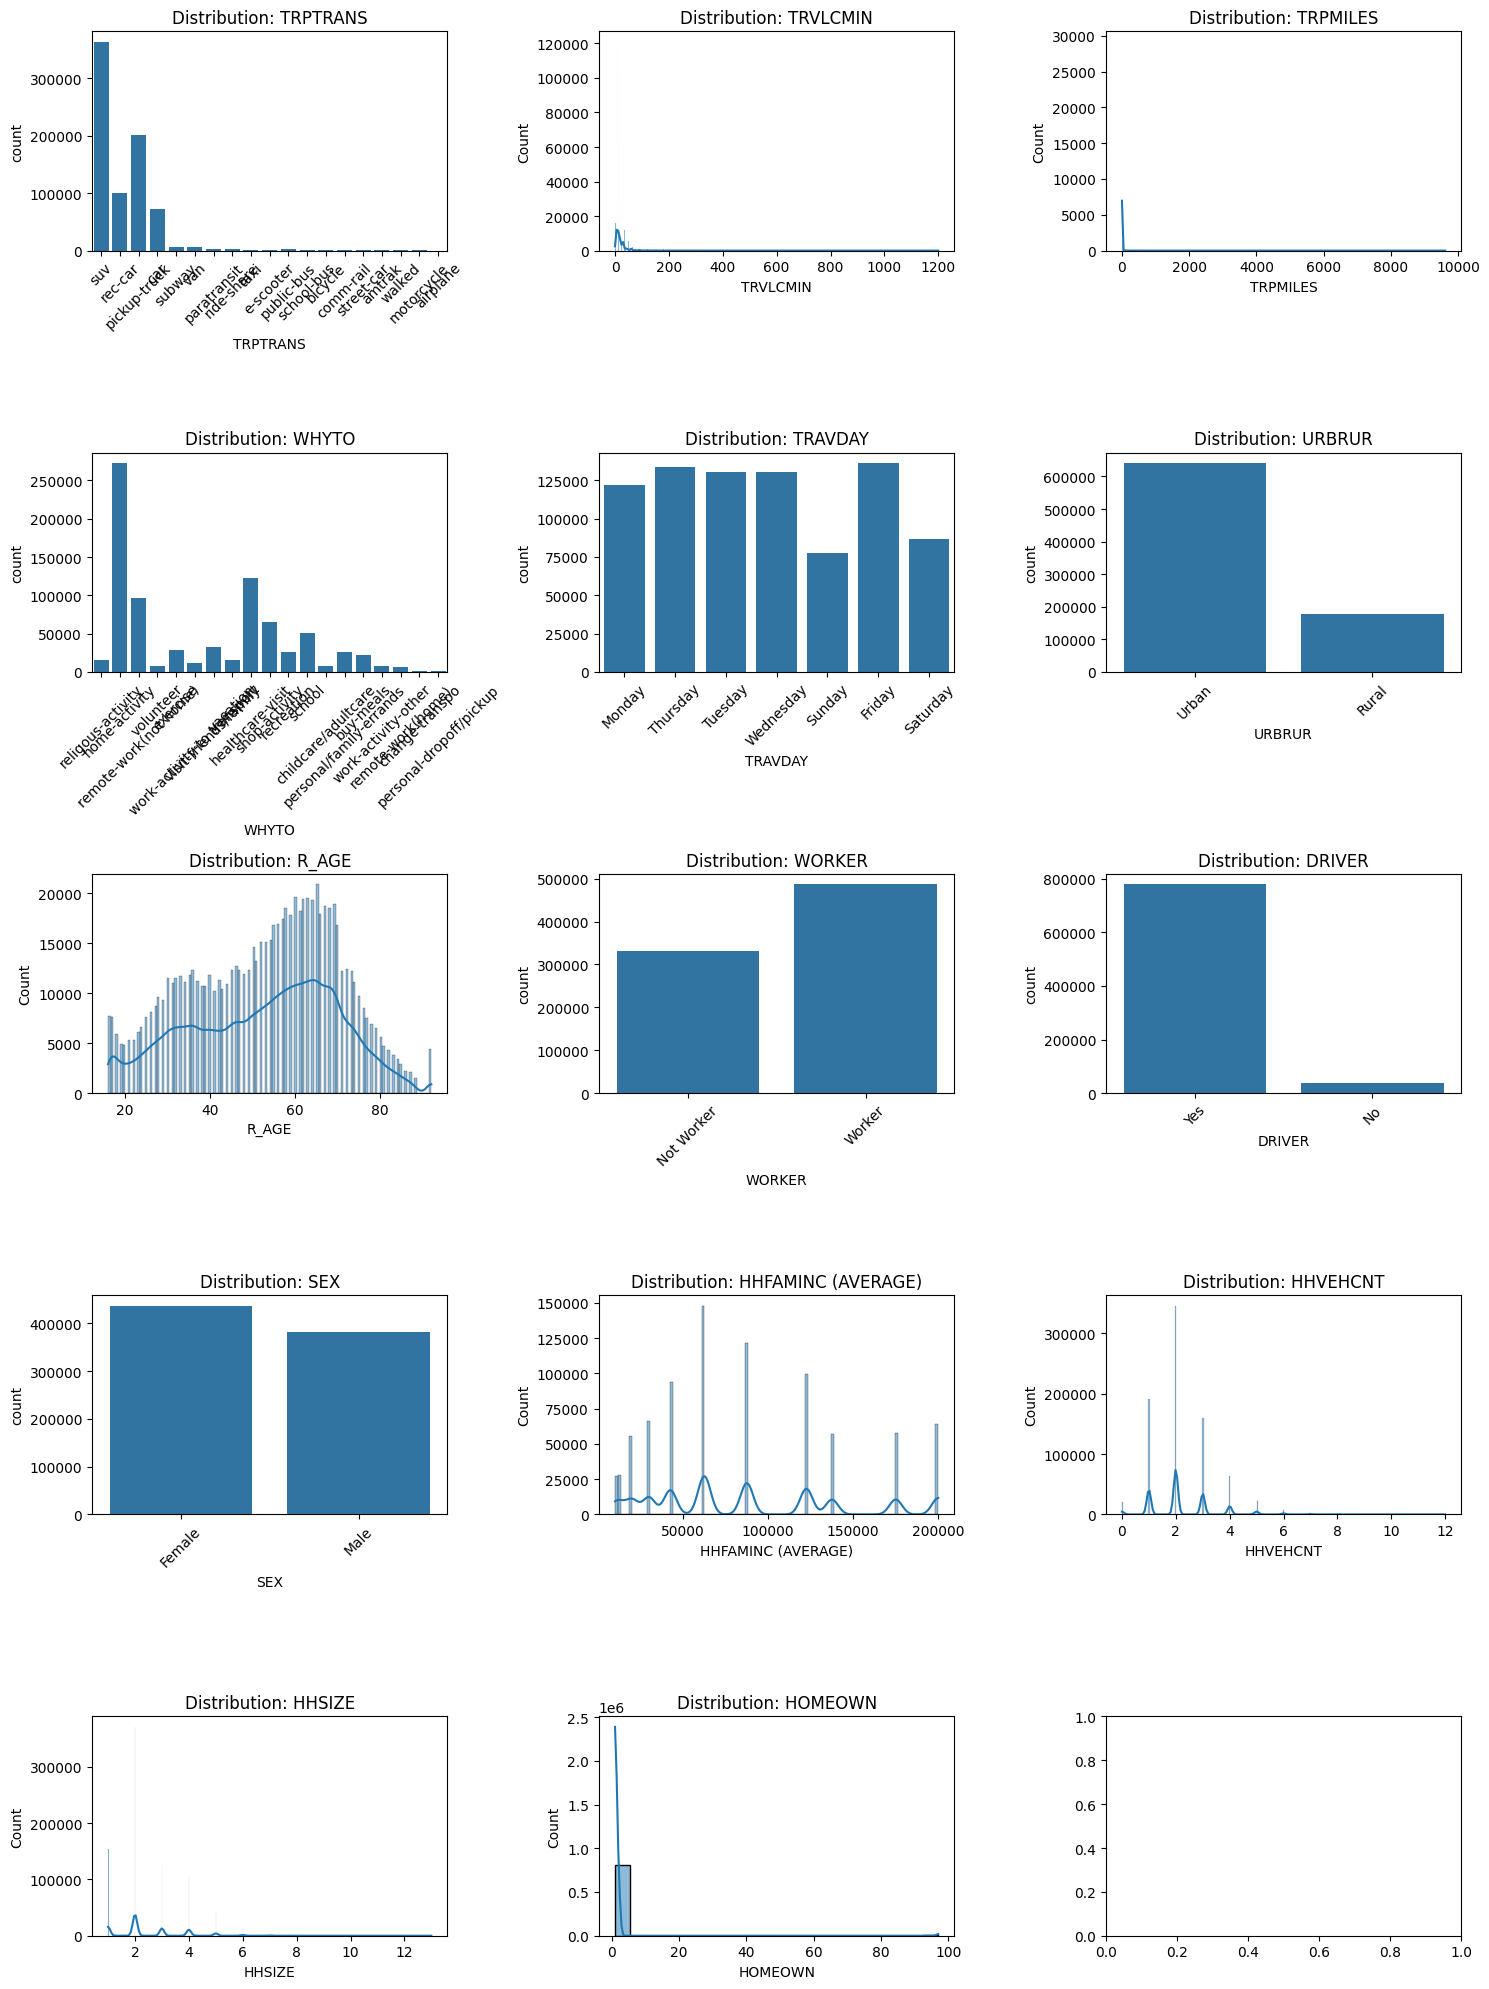

In [15]:
skip_cols = ['HOUSEID', 'PERSONID', 'TRIPTRANS']
cols_to_plot = [col for col in df.columns if col not in skip_cols]

n_cols = 3
n_rows = math.ceil(len(cols_to_plot) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(5*n_cols, 4*n_rows))
axes = axes.flatten()

for i, col in enumerate(cols_to_plot):
    ax = axes[i]
    if df[col].dtype == 'object' or df[col].dtype.name == 'category':
        sns.countplot(data=df, x=col, ax=ax)
        ax.tick_params(axis='x', rotation=45)

    else:
        sns.histplot(data=df, x=col, kde=True, ax=ax)
    ax.set_title(f'Distribution: {col}')

plt.tight_layout()

In [16]:
df['TRAVDAY'].unique()

array(['Monday', 'Thursday', 'Tuesday', 'Wednesday', 'Sunday', 'Friday',
       'Saturday'], dtype=object)

In [17]:
day_order = day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

week_trip_sum = df.groupby('TRAVDAY')['TRPMILES'].sum().reindex(day_order).reset_index()

In [18]:
week_trip_sum.head()

,TRAVDAY,TRPMILES
0,Monday,1322551.654
1,Tuesday,1291127.569
2,Wednesday,1470375.553
3,Thursday,1435159.562
4,Friday,1613447.636


In [19]:
weekmiles_averages = df.groupby('TRAVDAY')['TRPMILES'].mean()

weekmiles_averages = weekmiles_averages.reindex(day_order)

In [20]:
weekmiles_averages

TRAVDAY
Monday       10.838100
Tuesday       9.876140
Wednesday    11.255688
Thursday     10.746234
Friday       11.836171
Saturday     11.769862
Sunday       12.970243
Name: TRPMILES, dtype: float64

In [21]:
df.to_csv('final_data.csv', index=False)